In [3]:
import jax
import jax.numpy as jnp
import jax.scipy.stats as stats
import numpy as np
import blackjax
import matplotlib.pyplot as plt

In [ ]:
observed = np.random.normal(-100,20,size = 10000)

def logdensity_fn(x):
    logpdf = stats.norm.logpdf(observed, x["loc"], x["scale"])
    return jnp.sum(logpdf) 


# Build the kernel
step_size = 1e-3
inverse_mass_matrix = jnp.array([1., 1.])
nuts = blackjax.nuts(logdensity_fn, step_size, inverse_mass_matrix)

# Initialize the state
initial_position = {"loc": 1., "scale": 2.}
state = nuts.init(initial_position)

# Iterate
rng_key = jax.random.key(0)
step = jax.jit(nuts.step)
for i in range(1_000):
    nuts_key = jax.random.fold_in(rng_key, i)
    state, _ = step(nuts_key, state)



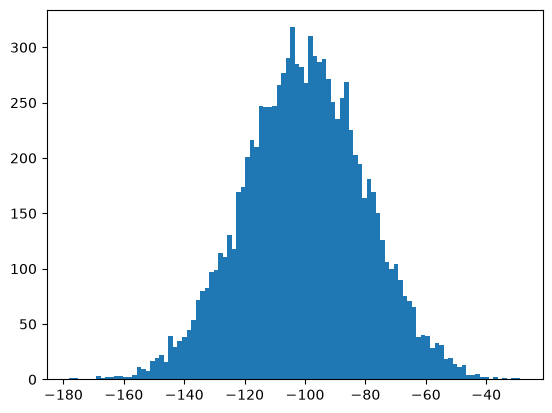

In [5]:
counts, bin_edges, patches = plt.hist(observed, bins=100, density=False)

In [6]:
import matplotlib.pyplot as plt
import numpy as np

import jax
import jax.numpy as jnp
import jax.scipy.stats as stats

import blackjax

In [7]:
from datetime import date
rng_key = jax.random.key(int(date.today().strftime("%Y%m%d")))

In [ ]:
loc, scale = 10, 20
observed = np.random.normal(loc, scale, size=1_000)


def logdensity_fn(loc, log_scale, observed=observed):
    """Univariate Normal"""
    scale = jnp.exp(log_scale)
    logjac = log_scale
    logpdf = stats.norm.logpdf(observed, loc, scale)
    return logjac + jnp.sum(logpdf)


logdensity = lambda x: logdensity_fn(**x)

fff

In [9]:
inv_mass_matrix = np.array([0.5, 0.01])
num_integration_steps = 60
step_size = 1e-3

hmc = blackjax.hmc(logdensity, step_size, inv_mass_matrix, num_integration_steps)

In [10]:
initial_position = {'loc': 1.0, 'log_scale': 1.0}
initial_state = hmc.init(initial_position)
initial_state

HMCState(position={'loc': 1.0, 'log_scale': 1.0}, logdensity=Array(-36280.535, dtype=float32), logdensity_grad={'loc': Array(1299.7736, dtype=float32, weak_type=True), 'log_scale': Array(67726.195, dtype=float32, weak_type=True)})

In [11]:
hmc_kernel = jax.jit(hmc.step)

def inference_loop(rng_key, kernel, initial_state, num_samples):
    @jax.jit
    def one_step(state, rng_key):
        state, _ = kernel(rng_key, state)
        return state, state

    keys = jax.random.split(rng_key, num_samples)
    _, states = jax.lax.scan(one_step, initial_state, keys)

    return states

In [ ]:
rng_key, sample_key = jax.random.split(rng_key)
states = inference_loop(rng_key, hmc_kernel, initial_state, 1000)
mcmc_samples = states.position
mcmc_samples["scale"] = jnp.exp(mcmc_samples["log_scale"]).block_until_ready()

In [13]:
mcmc_samples.keys()

dict_keys(['loc', 'log_scale', 'scale'])

## NUTS

In [14]:
inv_mass_matrix = np.array([0.5, 0.01])
step_size = 1e-3

nuts = blackjax.nuts(logdensity, step_size, inv_mass_matrix)

initial_position ={"loc": 1.0,"log_scale":1.0}
initial_state = nuts.init(initial_position)

In [15]:
rng_key, sample_key = jax.random.split(rng_key)
states = inference_loop(rng_key, nuts.step, initial_state, 4_000)

mcmc_samples = states.position
mcmc_samples["scale"] = jnp.exp(mcmc_samples["log_scale"]).block_until_ready()

In [16]:
mcmc_samples["loc"][-9:]

Array([10.722103, 10.920609, 10.918999, 11.148008, 11.163365, 11.207546,
       11.04711 , 11.021933, 11.230557], dtype=float32, weak_type=True)

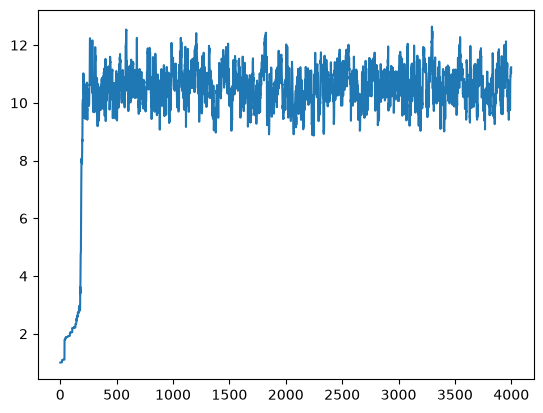

In [17]:
plt.plot(range(len(mcmc_samples["loc"])), mcmc_samples["loc"])
plt.show()

## Stan's Window Adaptation

In [18]:
%%time

warmup = blackjax.window_adaptation(blackjax.nuts, logdensity)
rng_key, warmup_key, sample_key = jax.random.split(rng_key, 3)
(state, parameters), _ = warmup.run(warmup_key, initial_position, num_steps=1000)

CPU times: user 1.34 s, sys: 37 ms, total: 1.38 s
Wall time: 1.28 s


In [24]:
state.position

{'loc': Array(10.144812, dtype=float32, weak_type=True),
 'log_scale': Array(2.9781008, dtype=float32, weak_type=True)}